# Prediciendo la diabetes

In [24]:
# Librerias

import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from pickle import dump

## Paso 1: Carga del conjunto de datos

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/4GeeksAcademy/decision-tree-project-tutorial/main/diabetes.csv')

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
columnas_con_ceros = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
]

df[columnas_con_ceros] = df[columnas_con_ceros].replace(0, np.nan)

for col in columnas_con_ceros:
  mediana = df[col].median()  
  df[col] = df[col].fillna(mediana)

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [6]:
print("Valores nulos antes de imputar:")
print(df[columnas_con_ceros].isnull().sum())

print("\nCantidad de ceros restantes:")
print((df[columnas_con_ceros] == 0).sum())

print("\nValores nulos después de imputar:")
print(df[columnas_con_ceros].isnull().sum())

Valores nulos antes de imputar:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Cantidad de ceros restantes:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Valores nulos después de imputar:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [7]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

X_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,2,84.0,72.0,29.0,125.0,32.3,0.304,21
618,9,112.0,82.0,24.0,125.0,28.2,1.282,50
346,1,139.0,46.0,19.0,83.0,28.7,0.654,22
294,0,161.0,50.0,29.0,125.0,21.9,0.254,65
231,6,134.0,80.0,37.0,370.0,46.2,0.238,46


## Paso 2: Construye un boosting

In [8]:
model = XGBClassifier(random_state=42)

model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [9]:
estrategia_cv = StratifiedKFold(n_splits=5,shuffle=True, random_state=42)

scores = cross_val_score(model, X_train, y_train, cv=estrategia_cv,scoring='accuracy')

print(scores)
print (f'Precisión Promedio: {scores.mean():.4f}+/-{scores.std():.4f}')



[0.75609756 0.69105691 0.74796748 0.7398374  0.79508197]
Precisión Promedio: 0.7460+/-0.0334


In [10]:
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0])

In [11]:
accuracy_score(y_test,y_pred)

0.7337662337662337

In [13]:
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [4, 6, 8, 10],
    'min_child_weight': [1, 5, 10],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2, 0.5],
    'reg_alpha': [0, 0.1, 1.0],
    'reg_lambda': [1.0, 5.0, 10.0],
    'n_estimators': [500, 1000]
}

In [14]:
grid_search = GridSearchCV(
    estimator = model, 
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs = -1
)

In [15]:
grid_search.fit(X_train, y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.6, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [4, 6, ...], ...}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [16]:
grid_search.best_params_

{'colsample_bytree': 0.6,
 'gamma': 0.1,
 'learning_rate': 0.01,
 'max_depth': 6,
 'min_child_weight': 5,
 'n_estimators': 500,
 'reg_alpha': 1.0,
 'reg_lambda': 5.0,
 'subsample': 1.0}

In [17]:
grid_search.best_score_

np.float64(0.7898973743835798)

In [18]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

accuracy_score(y_test, y_pred)

0.7792207792207793

In [19]:
resultados = pd.DataFrame(grid_search.cv_results_)

resultados

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_colsample_bytree,param_gamma,param_learning_rate,param_max_depth,param_min_child_weight,param_n_estimators,...,param_subsample,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.615620,0.017654,0.022003,0.006402,0.6,0.0,0.01,4,1,500,...,0.6,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.788618,0.813008,0.747967,0.723577,0.770492,0.768733,0.031077,6692
1,0.593830,0.019421,0.014768,0.006323,0.6,0.0,0.01,4,1,500,...,0.8,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.780488,0.813008,0.739837,0.731707,0.770492,0.767106,0.029306,8585
2,0.564241,0.010822,0.016957,0.005873,0.6,0.0,0.01,4,1,500,...,1.0,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.780488,0.821138,0.764228,0.739837,0.770492,0.775237,0.026576,1482
3,0.828458,0.146907,0.019896,0.007631,0.6,0.0,0.01,4,1,500,...,0.6,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.772358,0.829268,0.764228,0.739837,0.762295,0.773597,0.029853,2584
4,0.571159,0.018418,0.012933,0.002558,0.6,0.0,0.01,4,1,500,...,0.8,"{'colsample_bytree': 0.6, 'gamma': 0, 'learnin...",0.780488,0.813008,0.756098,0.747967,0.778689,0.775250,0.022698,1316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23323,0.374205,0.016642,0.007564,0.001044,1.0,0.5,0.10,10,10,1000,...,0.8,"{'colsample_bytree': 1.0, 'gamma': 0.5, 'learn...",0.764228,0.796748,0.731707,0.764228,0.754098,0.762202,0.020963,14356
23324,0.284409,0.006823,0.008135,0.001146,1.0,0.5,0.10,10,10,1000,...,1.0,"{'colsample_bytree': 1.0, 'gamma': 0.5, 'learn...",0.796748,0.804878,0.731707,0.715447,0.778689,0.765494,0.035632,10410
23325,0.373434,0.004586,0.008138,0.000995,1.0,0.5,0.10,10,10,1000,...,0.6,"{'colsample_bytree': 1.0, 'gamma': 0.5, 'learn...",0.747967,0.780488,0.731707,0.739837,0.737705,0.747541,0.017277,22455
23326,0.357523,0.009231,0.008079,0.001643,1.0,0.5,0.10,10,10,1000,...,0.8,"{'colsample_bytree': 1.0, 'gamma': 0.5, 'learn...",0.772358,0.821138,0.747967,0.747967,0.762295,0.770345,0.027020,5571


In [21]:
df_grid = resultados[['param_n_estimators','param_gamma','mean_test_score']]
df_grid

,param_n_estimators,param_gamma,mean_test_score
0,500,0.0,0.768733
1,500,0.0,0.767106
2,500,0.0,0.775237
3,500,0.0,0.773597
4,500,0.0,0.775250
...,...,...,...
23323,1000,0.5,0.762202
23324,1000,0.5,0.765494
23325,1000,0.5,0.747541
23326,1000,0.5,0.770345


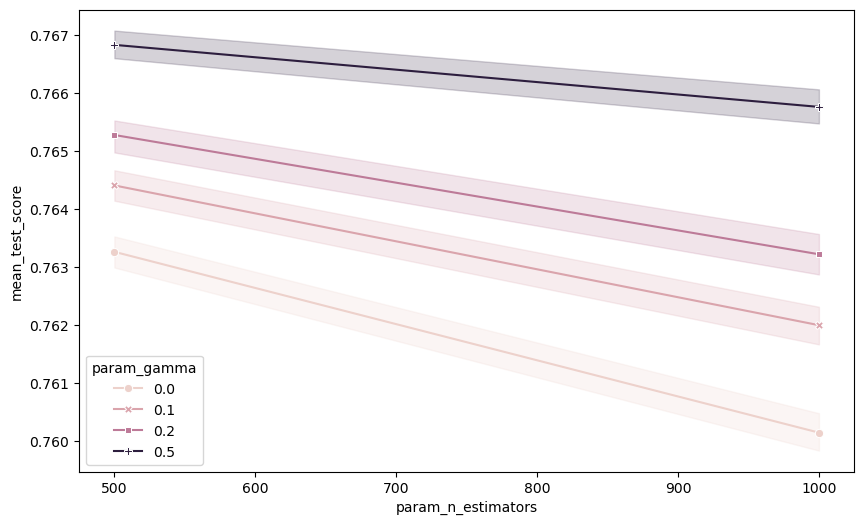

In [22]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=df_grid,
    x = 'param_n_estimators',
    y = 'mean_test_score',
    hue= 'param_gamma',
    style='param_gamma',
    markers=True,
    dashes= False
)

plt.show()

## Paso 3: Guarda el modelo

In [25]:
dump(best_model,open('../models/XGBoost_n_estimators_500.model','wb'))